# Process Simulation Assignment 2
## Optical Lithography: From Mask Pattern to Printed Resist Feature

**Course:** F437 Semiconductor Fabrication Technology
**Institute:** BITS Pilani, K K Birla Goa Campus

| | |
|---|---|
| **Group** | 7 |
| **Assigned case** | C ($\lambda$ = 0.248 µm, NA = 0.55, $D_{clear}$ = 50 mJ cm⁻²) |
| **Team members** | Ridhi (2024AAPS0032G), Rishika (2024AAPS0779G)|
| **Platform** | Python (NumPy, Matplotlib) |

---

### Contents
1. Task 1: Predict before coding
2. Task 2: Aerial-image simulator
3. Task 3: Lithographic transfer curve
4. Task 4: Focus and numerical aperture
5. Task 5: From dose to printed CD
6. Task 6: Verification, limitations and viva

**Units:** lengths in µm, dose in mJ cm⁻², spatial frequency in cycles/µm.

## Task 1: Predict before coding

**Case C:** $\lambda = 0.248\ \mu m$, NA $= 0.55$, $D_{clear} = 50\ mJ\,cm^{-2}$, with $k_1 = 0.60$, $k_2 = 0.50$.

### 1.1 Resolution and depth of focus

$$R = k_1\frac{\lambda}{NA} = 0.60 \times \frac{0.248}{0.55} = 0.271\ \mu m$$

$$DOF = k_2\frac{\lambda}{NA^2} = 0.50 \times \frac{0.248}{0.55^2} = 0.410\ \mu m$$

### 1.2 Pitches and accepted orders

Reference scale: $\lambda/NA = 0.248/0.55 = 0.451\ \mu m$. An order $m$ is accepted if $|m|\lambda/p \le NA$, so

$$m_{max} = \left\lfloor \frac{NA\,p}{\lambda} \right\rfloor$$

| Pitch | $p$ ($\mu m$) | $NA\,p/\lambda$ | $m_{max}$ | Accepted orders |
|---|---|---|---|---|
| $0.8\,\lambda/NA$ | 0.361 | 0.8 | 0 | $m = 0$ |
| $1.2\,\lambda/NA$ | 0.541 | 1.2 | 1 | $m = -1, 0, +1$ |
| $3.5\,\lambda/NA$ | 1.578 | 3.5 | 3 | $m = -3, -2, -1, 0, +1, +2, +3$ (but $c_{\pm 2} = 0$) |

### 1.3 Fourier coefficients ($f = 0.5$)

$$c_0 = f, \qquad c_m = \frac{\sin(\pi m f)}{\pi m}\quad (m \neq 0)$$

| Coefficient | Calculation | Value |
|---|---|---|
| $c_0$ | $f$ | 0.5000 |
| $c_1$ | $\sin(\pi/2)/\pi$ | 0.3183 |
| $c_2$ | $\sin(\pi)/2\pi$ | 0 |
| $c_3$ | $\sin(3\pi/2)/3\pi$ | $-0.1061$ |

All even orders vanish for a 50 % duty cycle, and $c_{-m} = c_m$.

### 1.4 Predictions (recorded before running the simulator)

| Pitch | Predicted image | Physical reason |
|---|---|---|
| $0.8\,\lambda/NA$ | Uniform | The only accepted order is $m = 0$ and also p=0.361 which is less than $\lambda/NA$ whis is equal to 0.451. |
| $1.2\,\lambda/NA$ | Approximately sinusoidal | An accepting order is $m = \pm 1$ and p=0.541 which lies between $\lambda/NA$ which is 0.451 and $2\,\lambda/NA$ which is 0.902. |
| $3.5\,\lambda/NA$ | Sharper-edged | An accepting order is $m = \pm 3$ and p=1.578 which is greater than $2\,\lambda/NA$ which is 0.902. | |

## Task 2: Build and explain the aerial-image simulator

**Case C:** $\lambda = 0.248\ \mu m$, NA $= 0.55$, $D_{clear} = 50\ mJ\,cm^{-2}$

### 2.1 Model implemented

| Step | Equation |
|---|---|
| Mask spectrum | $c_0 = f,\quad c_m = \dfrac{\sin(\pi m f)}{\pi m}\ (m \neq 0)$ |
| Pupil cutoff | accept order $m$ if $\lvert m\rvert\lambda/p \le NA$, so $m_{max} = \lfloor NA\,p/\lambda \rfloor$ |
| Complex field | $A(x,\Delta z) = \sum_{m=-m_{max}}^{m_{max}} c_m\, e^{i2\pi m x/p}\, e^{-i\pi\lambda\Delta z\,(m/p)^2}$ |
| Intensity | $I = \lvert A\rvert^2$ |
| Fixed normalisation | $I_N(x,\Delta z) = \dfrac{I(x,\Delta z)}{\max_x I(x,0)}$ (same best-focus peak for every focus) |
| Modulation | $M = \dfrac{I_{clear}-I_{dark}}{I_{clear}+I_{dark}},\quad I_{clear}=I_N(0),\ I_{dark}=I_N(p/2)$ |

In [28]:
import os
import csv
import numpy as np
import matplotlib.pyplot as plt

# ---- assigned case (group 7 -> Case C) ----
CASES = {"A": (0.365, 0.45, 80.0), "B": (0.365, 0.60, 80.0),
         "C": (0.248, 0.55, 50.0), "D": (0.248, 0.75, 50.0)}
CASE = "C"
lam, NA, Dclear = CASES[CASE]          # um, -, mJ/cm^2

K1, K2, F = 0.60, 0.50, 0.5            # screening constants, clear fraction
NX = 2001                               # x-points across one pitch
EPS, TOL = 1e-9, 1e-12
OUT = f"results/case_{CASE}"
os.makedirs(OUT, exist_ok=True)
ledger = []                             # verification ledger rows


def add(check, method, expected, ok, measured=""):
    """Add (or replace) a ledger row. Re-running a cell never duplicates a row."""
    method = f"{method}: {measured}" if measured != "" else method
    row = [check, method, expected, "PASS" if ok else "FAIL"]
    for i, r in enumerate(ledger):
        if r[0] == check:
            ledger[i] = row
            return
    ledger.append(row)


def mmax_of(p, lam, NA):
    """Highest accepted order: floor(NA p / lambda)."""
    return int(np.floor(NA * p / lam + EPS))


def coeffs(mm):
    """Fourier coefficients c_m for orders -mm..+mm (f = 0.5)."""
    m = np.arange(-mm, mm + 1)
    safe = np.where(m == 0, 1, m)
    c = np.where(m == 0, F, np.sin(np.pi * m * F) / (np.pi * safe))
    return m, c


def field(x, p, lam, NA, dz, mm=None):
    """Complex amplitude A(x, dz) = sum of accepted orders."""
    if mm is None:
        mm = mmax_of(p, lam, NA)
    m, c = coeffs(mm)
    phase = np.exp(1j * 2 * np.pi * np.outer(x, m) / p) * \
            np.exp(-1j * np.pi * lam * dz * (m / p) ** 2)
    return phase @ c


def intensity(x, p, lam, NA, dz, mm=None):
    return np.abs(field(x, p, lam, NA, dz, mm)) ** 2


def peak_ref(p, lam, NA, N=NX):
    """Best-focus peak: the SAME denominator for every focus condition."""
    x = np.linspace(-p / 2, p / 2, N)
    return intensity(x, p, lam, NA, 0.0).max()


def IN(x, p, lam, NA, dz, ref, mm=None):
    return intensity(x, p, lam, NA, dz, mm) / ref


def modulation(p, lam, NA, dz, ref, mm=None):
    Ic, Id = IN(np.array([0.0, p / 2]), p, lam, NA, dz, ref, mm)
    return (Ic - Id) / (Ic + Id), Ic, Id


def printed_cd(x, D, Dclear):
    """Opening CD from linearly interpolated crossings (resist clears where D >= Dclear)."""
    if D[np.argmin(np.abs(x))] < Dclear * (1 - TOL):
        return 0.0
    r = x >= 0
    xr, Dr = x[r], D[r]
    below = np.where(Dr < Dclear * (1 - TOL))[0]
    if below.size == 0:
        return x[-1] - x[0]            # whole pitch clears
    j = below[0]
    xc = xr[j - 1] + (Dclear - Dr[j - 1]) * (xr[j] - xr[j - 1]) / (Dr[j] - Dr[j - 1])
    return 2 * xc


def cd_at(p, lam, NA, Dclear, dose_ratio, dz, N=NX):
    x = np.linspace(-p / 2, p / 2, N)
    ref = peak_ref(p, lam, NA, N)
    Dt = Dclear / IN(np.array([p / 4]), p, lam, NA, 0.0, ref)[0]
    D = dose_ratio * Dt * IN(x, p, lam, NA, dz, ref)
    return printed_cd(x, D, Dclear), Dt


print(f"Case {CASE}: lambda = {lam} um, NA = {NA}, Dclear = {Dclear} mJ/cm^2")

Case C: lambda = 0.248 um, NA = 0.55, Dclear = 50.0 mJ/cm^2


In [29]:
R = K1 * lam / NA
DOF = K2 * lam / NA ** 2
print(f"R   = {R:.4f} um")
print(f"DOF = {DOF:.4f} um")

facs = [0.8, 1.2, 3.5]
pitches = [f * lam / NA for f in facs]
for f, p in zip(facs, pitches):
    mm = mmax_of(p, lam, NA)
    print(f"p = {f} lambda/NA = {p:.4f} um  ->  m_max = {mm}, accepted orders = {list(range(-mm, mm + 1))}")

_, c = coeffs(3)
print("c0 = %.4f, c1 = %.4f, c2 = %.4f, c3 = %.4f" % (c[3], c[4], c[5], c[6]))

R   = 0.2705 um
DOF = 0.4099 um
p = 0.8 lambda/NA = 0.3607 um  ->  m_max = 0, accepted orders = [0]
p = 1.2 lambda/NA = 0.5411 um  ->  m_max = 1, accepted orders = [-1, 0, 1]
p = 3.5 lambda/NA = 1.5782 um  ->  m_max = 3, accepted orders = [-3, -2, -1, 0, 1, 2, 3]
c0 = 0.5000, c1 = 0.3183, c2 = 0.0000, c3 = -0.1061


p = 0.8 lambda/NA: m_max = 0, I_clear = 1.0000, I_dark = 1.0000, M = 0.0000, peak I_N = 1.0000
p = 1.2 lambda/NA: m_max = 1, I_clear = 1.0000, I_dark = 0.0144, M = 0.9715, peak I_N = 1.0000
p = 3.5 lambda/NA: m_max = 3, I_clear = 0.7060, I_dark = 0.0047, M = 0.9867, peak I_N = 1.0000
  build-up p=3.5: m=0 only         M = 0.0000, max I_N = 0.2065, min I_N = 0.2065
  build-up p=3.5: m=0, +/-1        M = 0.9715, max I_N = 1.0673, min I_N = 0.0000
  build-up p=3.5: m=0, +/-1, +/-3  M = 0.9867, max I_N = 1.0000, min I_N = 0.0000


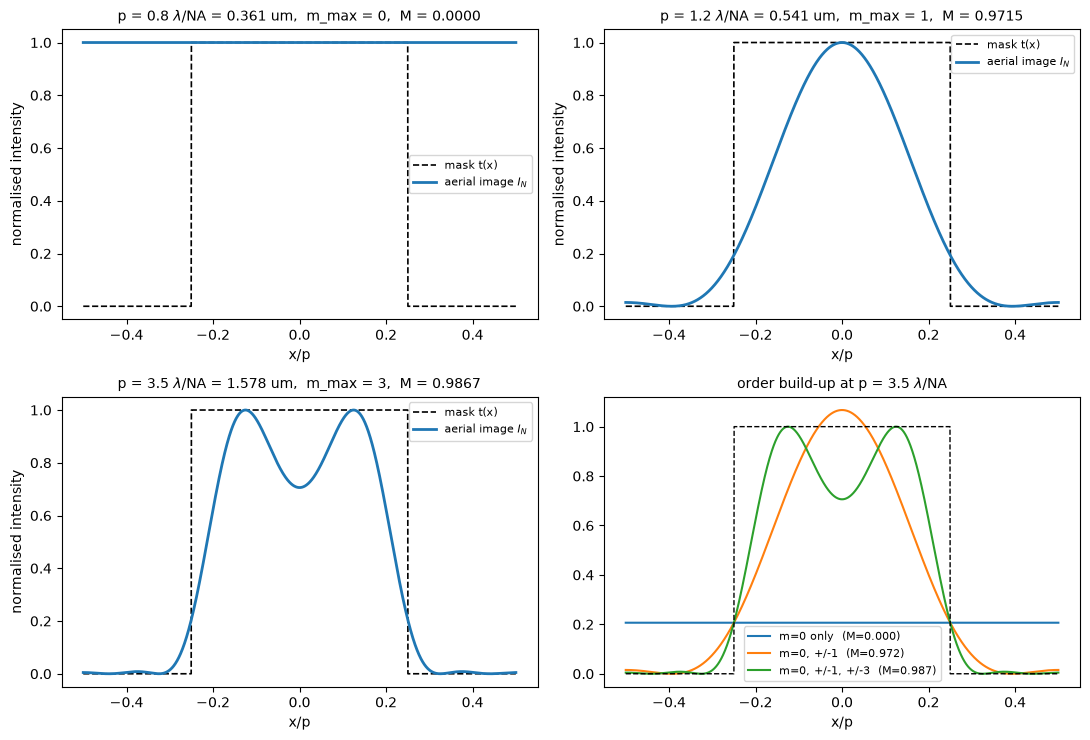


Symmetry error = 1.22e-15, min intensity = 1.97e-07, m=0-only deviation from 1 = 0.0e+00


In [30]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7.5))
Ms = {}
for ax, f, p in zip(axs.flat[:3], facs, pitches):
    x = np.linspace(-p / 2, p / 2, NX)
    ref = peak_ref(p, lam, NA)
    I = IN(x, p, lam, NA, 0.0, ref)
    t = np.where(np.abs(x) <= p / 4, 1.0, 0.0)          # ideal binary mask: clear for |x| <= p/4
    M, Ic, Id = modulation(p, lam, NA, 0.0, ref)
    Ms[f] = M
    mm = mmax_of(p, lam, NA)
    ax.plot(x / p, t, "k--", lw=1.2, label="mask t(x)")
    ax.plot(x / p, I, "C0", lw=2, label="aerial image $I_N$")
    ax.set_title(f"p = {f} $\\lambda$/NA = {p:.3f} um,  m_max = {mm},  M = {M:.4f}", fontsize=10)
    ax.set_xlabel("x/p"); ax.set_ylabel("normalised intensity"); ax.legend(fontsize=8)
    print(f"p = {f} lambda/NA: m_max = {mm}, I_clear = {Ic:.4f}, I_dark = {Id:.4f}, M = {M:.4f}, peak I_N = {I.max():.4f}")

# build-up of the 3.5 lambda/NA image (explains zero order, first pair, third pair)
p = pitches[2]
x = np.linspace(-p / 2, p / 2, NX); ref = peak_ref(p, lam, NA)
ax = axs[1, 1]
for mm, lab in [(0, "m=0 only"), (1, "m=0, +/-1"), (3, "m=0, +/-1, +/-3")]:
    I = IN(x, p, lam, NA, 0.0, ref, mm)
    M = modulation(p, lam, NA, 0.0, ref, mm)[0]
    ax.plot(x / p, I, label=f"{lab}  (M={M:.3f})")
    print(f"  build-up p=3.5: {lab:16s} M = {M:.4f}, max I_N = {I.max():.4f}, min I_N = {I.min():.4f}")
ax.plot(x / p, np.where(np.abs(x) < p / 4, 1.0, 0.0), "k--", lw=1)
ax.set_title("order build-up at p = 3.5 $\\lambda$/NA", fontsize=10)
ax.set_xlabel("x/p"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/fig1_order_capture.png", dpi=150); plt.show()

# ---- Task 2.4 verification checks ----
def best(p_):
    xx = np.linspace(-p_ / 2, p_ / 2, NX)
    return xx, IN(xx, p_, lam, NA, 0.0, peak_ref(p_, lam, NA))

sym = max(np.abs(best(q)[1] - best(q)[1][::-1]).max() for q in pitches)
mins = min(best(q)[1].min() for q in pitches)
I0 = best(pitches[0])[1]
pk = max(best(q)[1].max() for q in pitches)
ev = max(abs(coeffs(20)[1][20 + k]) for k in (2, 4, 6, 8, 10))
_, cc = coeffs(20001)
p1 = pitches[1]; x1 = np.linspace(-p1 / 2, p1 / 2, NX); r1 = peak_ref(p1, lam, NA)
tal = np.abs(IN(x1, p1, lam, NA, 2 * p1 ** 2 / lam, r1) - IN(x1, p1, lam, NA, 0.0, r1)).max()

add("I_N(x) = I_N(-x), best focus, 3 pitches", "max |I(x)-I(-x)|", "~0", sym < 1e-10, f"{sym:.2e}")
add("Non-negative intensity", "min I_N over 3 pitches", ">= 0", mins >= 0, f"{mins:.2e}")
add("Only m = 0 accepted (p = 0.8 lambda/NA)", "max|I_N - 1| and M", "I_N = 1, M = 0",
    np.abs(I0 - 1).max() < 1e-12 and abs(Ms[0.8]) < 1e-12, f"{np.abs(I0-1).max():.1e}, M = {Ms[0.8]:.1e}")
add("Peak normalisation", "max I_N at best focus", "= 1", abs(pk - 1) < 1e-12, f"{pk:.6f}")
add("Even c_m vanish (f = 0.5)", "max |c2, c4 ... c10|", "0", ev < 1e-12, f"{ev:.1e}")
add("Parseval: sum c_m^2 = f", "sum over |m| <= 20001", "0.5 within 1e-4", abs(np.sum(cc**2) - 0.5) < 1e-4, f"{np.sum(cc**2):.5f}")
add("Talbot self-imaging (m<=1, dz = 2p^2/lambda)", "max |I(dz)-I(0)|", "~0", tal < 1e-10, f"{tal:.1e}")
print(f"\nSymmetry error = {sym:.2e}, min intensity = {mins:.2e}, m=0-only deviation from 1 = {np.abs(I0-1).max():.1e}")

### 2.2 Mask and best-focus aerial image

**Figure 1.** Ideal mask transmission and best-focus aerial image vs. $x/p$ for
$p = 0.8,\ 1.2,\ 3.5\ \lambda/NA$, with $m_{max}$ and $M$ stated on each panel. The fourth
panel builds up the $3.5\,\lambda/NA$ image one order group at a time.

| Pitch | $m_{max}$ | $I_{clear}$ | $I_{dark}$ | $M$ |
|---|---|---|---|---|
| $0.8\,\lambda/NA$ | 0 | 1.0000 | 1.0000 | 0.0000 |
| $1.2\,\lambda/NA$ | 1 | 1.0000 | 0.0144 | 0.9715 |
| $3.5\,\lambda/NA$ | 3 | 0.7060 | 0.0047 | 0.9867 |

### 2.3 Comparison with predictions

| Pitch | Predicted | Simulated | Agrees? |
|---|---|---|---|
| $0.8\,\lambda/NA$ | uniform | flat, $I_N = 1$, $M = 0$ | yes |
| $1.2\,\lambda/NA$ | approx. sinusoidal | cosine-like fringe, $M = 0.9715$ | yes |
| $3.5\,\lambda/NA$ | sharper-edged | steeper edges with a flatter top and ripple, $M = 0.9867$ | yes |

- **Zero order ($m=0$):** carries no spatial information. It sets the average (DC)
  intensity, $c_0^2$. Alone, it gives a flat image: at $3.5\,\lambda/NA$ the level is
  $I_N = 0.2065$ everywhere and $M = 0$.
- **First-order pair ($m=\pm1$):** interferes with $m=0$ to form the fundamental cosine
  fringe, $A = c_0 + 2c_1\cos(2\pi x/p)$. This creates almost all of the contrast
  ($M$ from 0 to 0.9715) but gives a rounded profile. It also overshoots: with $m=0,\pm1$
  only, the peak is $I_N = 1.067$.
- **Third-order pair ($m=\pm3$):** $c_3 = -0.106$ is negative, so it subtracts at the clear
  centre (the centre drops from 1.067 to 0.706 of the final peak) and cancels the residual
  field in the dark region ($A(p/2)$ goes from $-0.137$ to $+0.076$). The edges steepen,
  the top flattens with some ripple, and $M$ rises only slightly (0.9715 to 0.9867).
- **Caveat:** at $3.5\,\lambda/NA$ the improvement is mainly in edge steepness. $M$
  barely changes, and because the peak is off-centre, $I_{clear} = I_N(0)$ understates
  the true peak.

### 2.4 Verification

| Check | Method | Expected | Outcome |
|---|---|---|---|
| Symmetry about $x=0$ | max $\lvert I(x)-I(-x)\rvert$, 3 pitches | ≈ 0 | $1.2\times10^{-15}$, PASS |
| Non-negative intensity | min $I_N$ | ≥ 0 | $2.0\times10^{-7}$, PASS |
| $m=0$ only ($0.8\,\lambda/NA$) | $\lvert I_N - 1\rvert$, $M$ | $I_N=1$, $M=0$ | $0$, $0$, PASS |
| Peak normalisation | max $I_N$ at best focus | 1 | 1.000000, PASS |
| Even $c_m$ vanish | max $\lvert c_2,\dots,c_{10}\rvert$ | 0 | $1.9\times10^{-17}$, PASS |
| Parseval | $\sum c_m^2$ | 0.5 | 0.49999, PASS |
| Talbot self-imaging | $\Delta z = 2p^2/\lambda$ | $I(\Delta z) = I(0)$ | $5.6\times10^{-16}$, PASS |

## Task 3: Lithographic transfer curve (best-focus modulation vs 1/p)

For 301 spatial frequencies $1/p$ from $0.15\,NA/\lambda$ to $1.25\,NA/\lambda$, the best-focus
modulation $M = (I_{clear}-I_{dark})/(I_{clear}+I_{dark})$ is computed with $I_{clear}=I_N(0)$,
$I_{dark}=I_N(p/2)$ and the best-focus peak of that pitch as normaliser (2001 x-points per pitch).
The first-order cutoff is $NA/\lambda = 0.55/0.248 = 2.218$ cycles/µm.

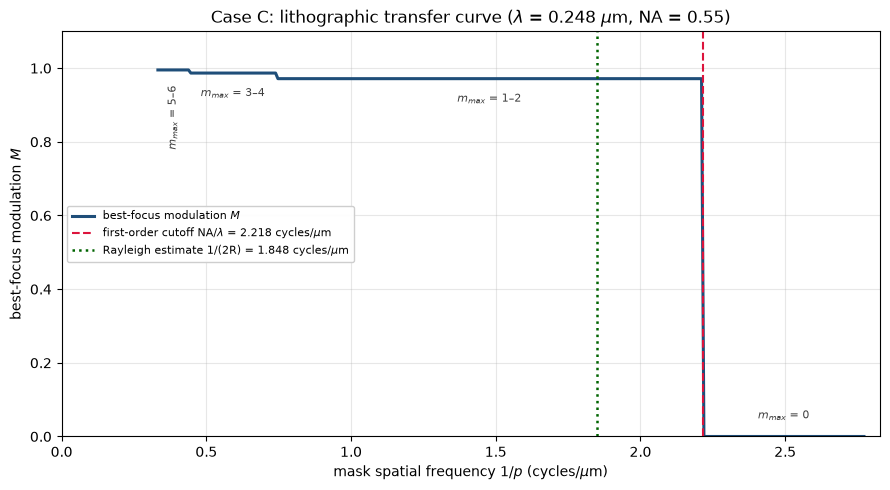

1/p = 0.333-0.438 cycles/um  m_max = [np.int64(5), np.int64(6)]  M = 0.9952
1/p = 0.447-0.739 cycles/um  m_max = [np.int64(3), np.int64(4)]  M = 0.9867
1/p = 0.747-2.211 cycles/um  m_max = [np.int64(1), np.int64(2)]  M = 0.9715
1/p = 2.219-2.772 cycles/um  m_max = [np.int64(0)]  M = 0.0000
M at Rayleigh frequency 1.848 cycles/um = 0.9715; cutoff = 2.218 cycles/um


In [35]:
fc     = NA / lam                                  # first-order cutoff [cycles/um]
NF     = 301                                       # frequency samples (>= 150 required)
freq   = np.linspace(0.15 * fc, 1.25 * fc, NF)     # 1/p [cycles/um]

Mcurve = np.zeros(NF)
mm_arr = np.zeros(NF, dtype=int)
for k, f_k in enumerate(freq):
    p_k = 1.0 / f_k
    Mcurve[k] = modulation(p_k, lam, NA, 0.0, peak_ref(p_k, lam, NA))[0]
    mm_arr[k] = mmax_of(p_k, lam, NA)

# Rayleigh screening estimate: R = k1*lam/NA is a half-pitch, so the pitch is 2R
f_ray = 1.0 / (2 * (K1 * lam / NA))                # = fc / 1.2

# ---- save data ----
with open(f"{OUT}/task3_transfer_curve.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["freq_cycles_per_um", "freq_over_NA_lam", "pitch_um", "mmax", "M"])
    for f_k, mm_k, M_k in zip(freq, mm_arr, Mcurve):
        w.writerow([f"{f_k:.6f}", f"{f_k / fc:.6f}", f"{1 / f_k:.6f}", mm_k, f"{M_k:.6f}"])

# ---- group plateaus: m_max values that give the same M are merged (c2 = c4 = 0) ----
groups, start = [], 0
for k in range(1, NF + 1):
    if k == NF or abs(Mcurve[k] - Mcurve[start]) > 1e-9:
        groups.append((start, k - 1))
        start = k

# ---- plot ----
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(freq, Mcurve, color="#1f4e79", lw=2.2, label="best-focus modulation $M$")
ax.axvline(fc, color="crimson", ls="--", lw=1.5,
           label=rf"first-order cutoff NA/$\lambda$ = {fc:.3f} cycles/$\mu$m")
ax.axvline(f_ray, color="darkgreen", ls=":", lw=1.8,
           label=rf"Rayleigh estimate 1/(2R) = {f_ray:.3f} cycles/$\mu$m")

# plateau labels sit INSIDE the axes, just under each plateau, so nothing is clipped
span = freq[-1] - freq[0]
for a, b in groups:
    lo, hi = mm_arr[b], mm_arr[a]                  # m_max falls as frequency rises
    txt = f"$m_{{max}}$ = {lo}" if lo == hi else f"$m_{{max}}$ = {lo}\u2013{hi}"
    narrow = (freq[b] - freq[a]) < 0.09 * span
    y, va = (Mcurve[a] - 0.04, "top") if Mcurve[a] > 0.05 else (0.04, "bottom")   # M = 0 plateau: label above the line
    ax.text((freq[a] + freq[b]) / 2, y, txt, fontsize=8, color="0.25",
            ha="center", va=va, rotation=90 if narrow else 0)

ax.set_xlim(0, freq[-1] * 1.02)
ax.set_ylim(0, 1.1)
ax.set_xlabel(r"mask spatial frequency $1/p$ (cycles/$\mu$m)")
ax.set_ylabel("best-focus modulation $M$")
ax.set_title(rf"Case {CASE}: lithographic transfer curve ($\lambda$ = {lam} $\mu$m, NA = {NA})")
ax.grid(alpha=0.3)
ax.legend(loc="center left", fontsize=8, framealpha=0.95)
fig.tight_layout()
fig.savefig(f"{OUT}/task3_transfer_curve.png", dpi=200)
plt.show()

# ---- printed summary + ledger entries ----
for a, b in groups:
    print(f"1/p = {freq[a]:.3f}-{freq[b]:.3f} cycles/um  m_max = {sorted({mm_arr[b], mm_arr[a]})}  M = {Mcurve[a]:.4f}")
M_ray = np.interp(f_ray, freq, Mcurve)
print(f"M at Rayleigh frequency {f_ray:.3f} cycles/um = {M_ray:.4f}; cutoff = {fc:.3f} cycles/um")

above = Mcurve[freq > fc * (1 + 1e-9)]
add("Task 3: M = 0 above cutoff NA/lambda", "max |M| for 1/p > NA/lambda", "0 (only m = 0 accepted)",
    np.all(np.abs(above) < 1e-12), f"{np.abs(above).max():.1e}")
add("Task 3: M constant within each plateau", "max spread of M inside each group",
    "0 (image set by accepted orders only)",
    all(np.ptp(Mcurve[a:b + 1]) < 1e-9 for a, b in groups), f"{len(groups)} plateaus")
add("Task 3: frequency sweep size", "number of 1/p samples", ">= 150", NF >= 150, f"{NF}")

**Figure 3.** Best-focus modulation $M$ against $1/p$ (cycles/µm), with the first-order cutoff and the Rayleigh estimate marked.

### 3.3 Steps, plateaus and the Rayleigh estimate

$M$ depends only on which orders are accepted, $m_{max} = \lfloor NA/(\lambda\,(1/p)) \rfloor$. Because $c_2 = c_4 = \dots = 0$, $M$ only changes when an **odd** order enters or leaves the pupil, so $m_{max} = 1,2$ give the same $M$ (0.9715), $m_{max} = 3,4$ give 0.9867, and $m_{max} = 5,6$ give 0.9952. The steps occur at $1/p = NA/(3\lambda) = 0.739$ and $NA/(5\lambda) = 0.444$ cycles/µm, where $m = \pm3$ and $\pm5$ are admitted. The abrupt drop to $M = 0$ at $1/p = NA/\lambda = 2.218$ cycles/µm occurs because the hard pupil rejects $m = \pm1$ completely, leaving only the flat zero order.

The Rayleigh estimate $R = k_1\lambda/NA$ corresponds to $p = 2R$, i.e. $1/p = 1.848$ cycles/µm ($0.833\,NA/\lambda$). The simulation still gives $M = 0.9715$ there, so the ideal pupil passes finer pitches than Rayleigh predicts. The ideal cutoff $p = \lambda/NA$ corresponds to $k_1 = 0.5$, while Rayleigh uses $k_1 = 0.6$ as a conservative practical margin. The two are related because both scale as $\lambda/NA$, but they are not identical: the cutoff is a sharp geometric condition on the first order, whereas Rayleigh is an empirical screening rule.

### 3.4 Pattern-modulation curve vs experimental MTF
This curve is the best-focus contrast of one specific pattern (a 50 % duty-cycle binary grating under coherent light), and it falls abruptly because the pupil is an ideal hard cutoff. A complete experimental lens MTF describes contrast transfer for any spatial frequency and rolls off gradually, because it includes partial coherence, aberrations, defocus, flare and detector or resist response.

## Task 4: Focus and numerical aperture

Working pitch $p = 1.5\,\lambda/NA = 0.6764\ \mu m$ (assigned NA), **held fixed** throughout.
$DOF = k_2\lambda/NA^2 = 0.4099\ \mu m$. For the NA sweep, $NA \to 1.2\times 0.55 = 0.66$ with
$\lambda$ and $p$ unchanged, giving $DOF = 0.2847\ \mu m$.

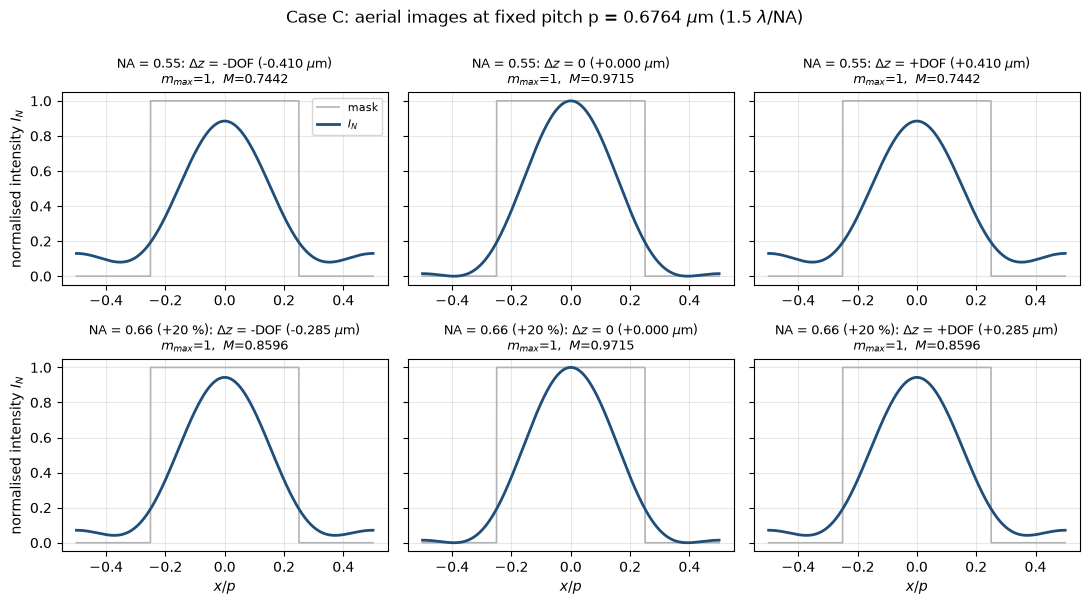

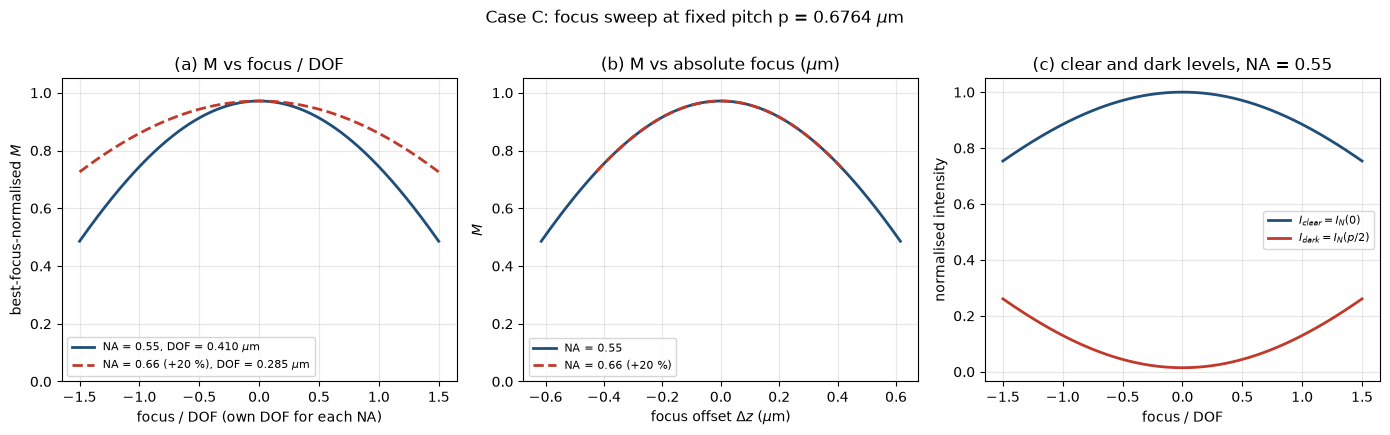

Working pitch p = 1.5 lam/NA = 0.6764 um (fixed)
NA = 0.55: m_max = 1, N*p/lam = 1.50, DOF = k2*lam/NA^2 = 0.4099 um, R = k1*lam/NA = 0.2705 um, cutoff pitch lam/NA = 0.4509 um
NA = 0.66 (+20 %): m_max = 1, N*p/lam = 1.80, DOF = k2*lam/NA^2 = 0.2847 um, R = k1*lam/NA = 0.2255 um, cutoff pitch lam/NA = 0.3758 um

M at -DOF, 0, +DOF:
  NA = 0.55: -DOF: M=0.7442 (Ic=0.885, Id=0.1297),  0: M=0.9715 (Ic=1.000, Id=0.0144),  +DOF: M=0.7442 (Ic=0.885, Id=0.1297)
  NA = 0.66 (+20 %): -DOF: M=0.8596 (Ic=0.943, Id=0.0712),  0: M=0.9715 (Ic=1.000, Id=0.0144),  +DOF: M=0.8596 (Ic=0.943, Id=0.0712)

NA = 0.55: M(sweep) max = 0.9715 at focus = +0.00 DOF; M min over sweep = 0.4858
NA = 0.55: I_clear falls from 1.000 (best focus) to 0.754 at -1.5 DOF

Extra check (NOT the Task 4 pitch): p = 1.5 lam/NA2 = 0.5636 um, M(+DOF2) = 0.7442 vs M(+DOF1) at the working pitch = 0.7442


In [36]:
pW   = 1.5 * lam / NA                 # working pitch [um], never changes below
NA2  = 1.2 * NA                       # NA increased by 20 %
DOF1 = K2 * lam / NA**2               # DOF at assigned NA   [um]
DOF2 = K2 * lam / NA2**2              # DOF at increased NA  [um]
systems = [(f"NA = {NA:.2f}", NA, DOF1), (f"NA = {NA2:.2f} (+20 %)", NA2, DOF2)]

xn = np.linspace(-0.5, 0.5, NX)       # x/p
x  = xn * pW


def M_analytic_m1(dz, p):
    """Closed form for m_max = 1.  With A = c0 + 2 c1 cos(2 pi x/p) e^{-i phi},
    phi = pi*lam*dz/p^2:  I_clear,dark = c0^2 + 4 c1^2 +/- 4 c0 c1 cos(phi),
    so  M = 4 c0 c1 cos(phi) / (c0^2 + 4 c1^2)  =  M(best focus) * cos(phi)."""
    c0, c1 = F, np.sin(np.pi * F) / np.pi
    return 4 * c0 * c1 * np.cos(np.pi * lam * dz / p**2) / (c0**2 + 4 * c1**2)


# ---- 4.1 aerial images at -DOF, 0, +DOF (both NA values) ----
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
img = {}                                              # stored for the checks below
for r, (lab, NAv, DOFv) in enumerate(systems):
    ref = peak_ref(pW, lam, NAv)                      # best-focus peak, fixed for all dz
    mmv = mmax_of(pW, lam, NAv)
    for c, (tag, dz) in enumerate([("-DOF", -DOFv), ("0", 0.0), ("+DOF", +DOFv)]):
        I = IN(x, pW, lam, NAv, dz, ref)
        M, Ic, Id = modulation(pW, lam, NAv, dz, ref)
        img[(r, tag)] = (I, M, Ic, Id)
        ax = axes[r, c]
        ax.plot(xn, (np.abs(xn) <= 0.25).astype(float), color="0.7", lw=1.2, label="mask")
        ax.plot(xn, I, color="#1f4e79", lw=2, label=r"$I_N$")
        ax.set_title(rf"{lab}: $\Delta z$ = {tag} ({dz:+.3f} $\mu$m)" "\n"
                     rf"$m_{{max}}$={mmv},  $M$={M:.4f}", fontsize=9)
        ax.grid(alpha=0.3)
        if r == 1:
            ax.set_xlabel("$x/p$")
        if c == 0:
            ax.set_ylabel("normalised intensity $I_N$")
axes[0, 0].legend(fontsize=8)
fig.suptitle(rf"Case {CASE}: aerial images at fixed pitch p = {pW:.4f} $\mu$m (1.5 $\lambda$/NA)", y=1.0)
fig.tight_layout()
fig.savefig(f"{OUT}/task4_images.png", dpi=200)
plt.show()

# ---- 4.2 / 4.3 focus sweep of M ----
u    = np.linspace(-1.5, 1.5, 241)                    # focus / DOF
curv = {}
for lab, NAv, DOFv in systems:
    ref = peak_ref(pW, lam, NAv)
    out = np.array([modulation(pW, lam, NAv, uu * DOFv, ref) for uu in u])
    curv[lab] = dict(M=out[:, 0], Ic=out[:, 1], Id=out[:, 2], DOF=DOFv)

fig, axs = plt.subplots(1, 3, figsize=(14, 4.3))
cols = ["#1f4e79", "#c0392b"]
for (lab, NAv, DOFv), col, ls in zip(systems, cols, ["-", "--"]):
    axs[0].plot(u, curv[lab]["M"], color=col, ls=ls, lw=2, label=f"{lab}, DOF = {DOFv:.3f} $\\mu$m")
    axs[1].plot(u * DOFv, curv[lab]["M"], color=col, ls=ls, lw=2, label=lab)
axs[0].set(xlabel="focus / DOF (own DOF for each NA)", ylabel="best-focus-normalised $M$",
           title="(a) M vs focus / DOF")
axs[1].set(xlabel=r"focus offset $\Delta z$ ($\mu$m)", ylabel="$M$",
           title=r"(b) M vs absolute focus ($\mu$m)")
l1 = curv[systems[0][0]]
axs[2].plot(u, l1["Ic"], color="#1f4e79", lw=2, label=r"$I_{clear}=I_N(0)$")
axs[2].plot(u, l1["Id"], color="#c0392b", lw=2, label=r"$I_{dark}=I_N(p/2)$")
axs[2].set(xlabel="focus / DOF", ylabel="normalised intensity",
           title=f"(c) clear and dark levels, {systems[0][0]}")
for a in axs:
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
for a in axs[:2]:
    a.set_ylim(0, 1.05)
fig.suptitle(f"Case {CASE}: focus sweep at fixed pitch p = {pW:.4f} $\\mu$m", y=1.0)
fig.tight_layout()
fig.savefig(f"{OUT}/task4_focus_sweep.png", dpi=200)
plt.show()

# ---- save data ----
with open(f"{OUT}/task4_focus_sweep.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["NA", "focus_over_DOF", "focus_um", "M", "I_clear", "I_dark"])
    for lab, NAv, DOFv in systems:
        d = curv[lab]
        for k, uu in enumerate(u):
            w.writerow([f"{NAv:.3f}", f"{uu:.4f}", f"{uu*DOFv:.5f}",
                        f"{d['M'][k]:.6f}", f"{d['Ic'][k]:.6f}", f"{d['Id'][k]:.6f}"])

# ---- printed summary ----
print(f"Working pitch p = 1.5 lam/NA = {pW:.4f} um (fixed)")
for lab, NAv, DOFv in systems:
    print(f"{lab}: m_max = {mmax_of(pW, lam, NAv)}, N*p/lam = {NAv*pW/lam:.2f}, "
          f"DOF = k2*lam/NA^2 = {DOFv:.4f} um, R = k1*lam/NA = {K1*lam/NAv:.4f} um, "
          f"cutoff pitch lam/NA = {lam/NAv:.4f} um")
print("\nM at -DOF, 0, +DOF:")
for r, (lab, NAv, DOFv) in enumerate(systems):
    print(f"  {lab}: " + ",  ".join(f"{t}: M={img[(r, t)][1]:.4f} (Ic={img[(r, t)][2]:.3f}, Id={img[(r, t)][3]:.4f})"
                                    for t in ["-DOF", "0", "+DOF"]))
l1 = curv[systems[0][0]]
kpk = np.argmax(l1["M"])
print(f"\n{systems[0][0]}: M(sweep) max = {l1['M'][kpk]:.4f} at focus = {u[kpk]:+.2f} DOF; "
      f"M min over sweep = {l1['M'].min():.4f}")
print(f"{systems[0][0]}: I_clear falls from {l1['Ic'][len(u)//2]:.3f} (best focus) to "
      f"{l1['Ic'][0]:.3f} at -1.5 DOF")

# ---- why DOF ~ 1/NA^2: same *normalised* pitch (p = 1.5 lam/NA2) at the new NA ----
pN = 1.5 * lam / NA2
refN = peak_ref(pN, lam, NA2)
MN = modulation(pN, lam, NA2, DOF2, refN)[0]
print(f"\nExtra check (NOT the Task 4 pitch): p = 1.5 lam/NA2 = {pN:.4f} um, M(+DOF2) = {MN:.4f} "
      f"vs M(+DOF1) at the working pitch = {img[(0, '+DOF')][1]:.4f}")

# ---- verification ledger entries ----
I_m, I_p = img[(0, "-DOF")][0], img[(0, "+DOF")][0]
sym_err = np.max(np.abs(I_m - I_p))
ana_err = max(np.max(np.abs(curv[l]["M"] - M_analytic_m1(u * d, pW))) for l, _, d in systems)
add("Task 4: I(x,+dz) = I(x,-dz)", "max |I_N(+DOF) - I_N(-DOF)|",
    "~0 (field at -dz is the conjugate of +dz)", sym_err < 1e-10, f"{sym_err:.1e}")
add("Task 4: M(focus) vs closed form (m_max = 1)", "max |M_num - M_analytic|",
    "agree to ~1e-9", ana_err < 1e-9, f"{ana_err:.1e}")
add("Task 4: DOF = k2 lam/NA^2", f"DOF {DOF1:.4f} um -> {DOF2:.4f} um", f"ratio = 1/1.2^2 = {1/1.44:.4f}",
    np.isclose(DOF2 / DOF1, 1 / 1.44), f"ratio = {DOF2/DOF1:.4f}")
add("Task 4: best-focus M equal for both NA", "compare m_max and M(0)", "same m_max = 1 -> identical image",
    mmax_of(pW, lam, NA) == mmax_of(pW, lam, NA2) and np.isclose(img[(0, '0')][1], img[(1, '0')][1]),
    f"M = {img[(0, '0')][1]:.4f} and {img[(1, '0')][1]:.4f}")

**Figure 4.** (top) Aerial images at $-$DOF, 0, $+$DOF for NA = 0.55 and 0.66, with $M$ on each
panel. (bottom) $M$ vs. focus/DOF, $M$ vs. absolute focus, and the clear/dark levels.

| | NA = 0.55 | NA = 0.66 (+20 %) |
|---|---|---|
| DOF $=k_2\lambda/NA^2$ | 0.4099 µm | 0.2847 µm |
| $m_{max}$ at $p=0.6764$ µm | 1 | 1 |
| $M$ at best focus | 0.9715 | 0.9715 |
| $M$ at $\pm$DOF | 0.7442 | 0.8596 |
| $M$ at $\pm1.5$ DOF | 0.4858 | 0.7257 |
| $R=k_1\lambda/NA$ | 0.2705 µm | 0.2255 µm |
| Cutoff pitch $\lambda/NA$ | 0.4509 µm | 0.3758 µm |

### 4.1 Symmetry
$M(-\text{DOF}) = M(+\text{DOF}) = 0.7442$ and the two images are identical. The defocus phase
$-\pi\lambda\Delta z\,(m/p)^2$ depends on $m^2$ and changes sign with $\Delta z$. For a mask with
real, even coefficients the field at $-\Delta z$ is the complex conjugate of the field at
$+\Delta z$, so $I$ is even in $\Delta z$. For $m_{max}=1$ this gives
$M = M_0\cos\varphi$ with $\varphi = \pi\lambda\Delta z/p^2 = 40^\circ$ at DOF. Real asymmetry would
need aberrations (e.g. spherical) or stack effects, which this model does not include.

### 4.2 Focus sweep
$M$ falls smoothly from 0.9715 to 0.7442 at DOF and 0.4858 at 1.5 DOF. The cause is two effects:
$I_{dark}$ rises (0.014 to 0.130 at DOF) and $I_{clear}$ falls (1.000 to 0.885).

### 4.3 Effect of +20 % NA
At this fixed pitch $NA\,p/\lambda$ goes from 1.5 to 1.8, so $m_{max}$ stays 1, and the best-focus
image and $M$ are unchanged. The simulator's defocus factor does not contain NA, so $M$ vs.
absolute focus is identical for both NA (panel b). The NA = 0.66 curve only looks flatter in
panel (a) because its DOF is shorter (0.2847 µm).

### 4.4 Trade-off and immersion
- **What improves:** $R$ shrinks from 0.2705 to 0.2255 µm and the cutoff pitch from 0.451 to
  0.376 µm, so finer pitches become printable, and more orders are captured for pitches that
  were previously cut off.
- **What becomes more sensitive:** $DOF\propto 1/NA^2$ falls by a factor $1/1.44$. For a pitch
  scaled to the new NA ($p=1.5\lambda/NA_2$) the extra check gives $M(+DOF_2) = 0.7442$, the same
  as before, because the defocus phase at one DOF is the same. A smaller feature therefore
  needs tighter focus control in micrometres.
- **Immersion:** $NA = n\sin\theta$, and $\sin\theta\le 1$. In air $n\approx1$, so $NA<1$.
  Filling the gap between the lens and the wafer with a liquid of $n>1$ (water, $n\approx1.44$
  at 193 nm) raises the limit, which is how $NA>1$ is reached.

## Task 5: From dose to printed CD

Working pitch $p = 1.5\,\lambda/NA = 0.6764\ \mu m$, target opening $CD_t = p/2 = 0.3382\ \mu m$.
Dose: $D(x) = D_0\,I_N(x)$. Positive resist clears where $D \ge D_{clear} = 50$ mJ/cm².
The best-focus target dose is $D_{target} = D_{clear}/I_N(p/4,0)$. The same $D_{target}$ is used for
the defocused curve. CD comes from linearly interpolated threshold crossings.

Working pitch p = 0.6764 um, m_max = 1, target CD = p/2 = 0.3382 um
I_N(p/4, 0) = 0.19351  ->  D_target = D_clear / I_N(p/4, 0) = 258.38 mJ/cm^2

dose/D_t       dose |   CD (um)  CD/CD_t |  CD (um) @+0.75DOF  CD/CD_t
    0.80     206.70 |    0.3182   0.9409 |             0.3155   0.9329
    1.00     258.38 |    0.3382   1.0000 |             0.3382   1.0000
    1.20     310.06 |    0.3529   1.0436 |             0.3555   1.0512


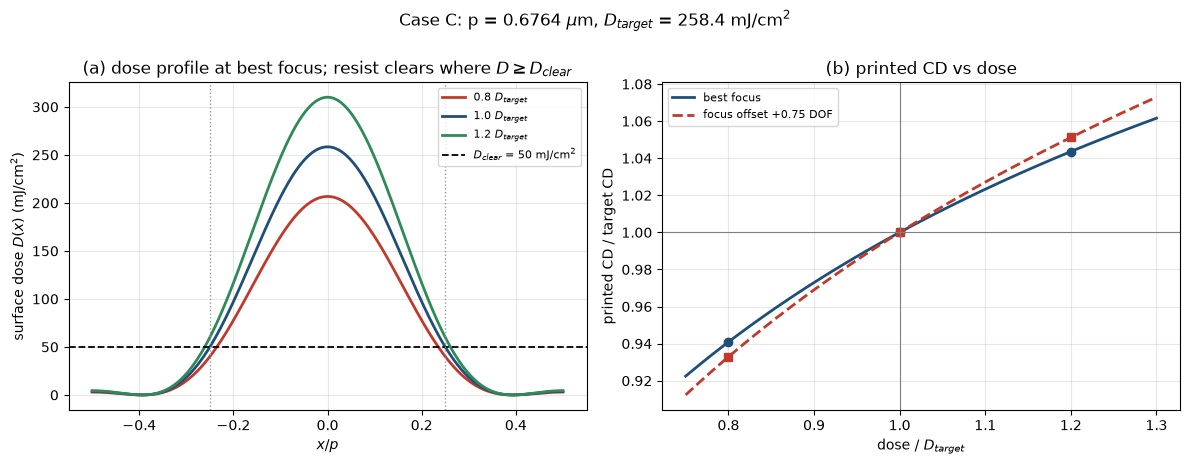

Dose sensitivity at 1.0 D_t, best focus: dCD/CD per dose/D_t = 0.250 (+1 % dose -> 0.25 % CD)
Dose sensitivity at 1.0 D_t, +0.75 DOF: dCD/CD per dose/D_t = 0.289 (+1 % dose -> 0.29 % CD)

Zero-order-only case: p = 0.8 lam/NA = 0.3607 um, m_max = 0
  I_N range = [1.000000, 1.000000], D_target = 50.00 mJ/cm^2
  printed CD over dose 0.75..1.30 D_t takes only values: [0.0, 0.360727] um (0 = nothing clears, 0.3607 = whole pitch clears)


In [33]:
pW    = 1.5 * lam / NA                    # working pitch [um]
DOF1  = K2 * lam / NA**2                  # DOF at assigned NA [um]
CDt   = pW / 2                            # target opening [um]
x     = np.linspace(-pW / 2, pW / 2, NX)
xn    = x / pW
refW  = peak_ref(pW, lam, NA)             # best-focus peak, fixed for all focus/dose

# ---- 5.1 best-focus target dose ----
IN_edge = IN(np.array([pW / 4]), pW, lam, NA, 0.0, refW)[0]       # I_N(p/4, 0)
D_target = Dclear / IN_edge                                       # mJ/cm^2
print(f"Working pitch p = {pW:.4f} um, m_max = {mmax_of(pW, lam, NA)}, target CD = p/2 = {CDt:.4f} um")
print(f"I_N(p/4, 0) = {IN_edge:.5f}  ->  D_target = D_clear / I_N(p/4, 0) = {D_target:.2f} mJ/cm^2")

# ---- 5.2 printed CD at 0.8, 1.0, 1.2 x target dose (best focus and +0.75 DOF) ----
dz_def = 0.75 * DOF1
rows = []
print(f"\n{'dose/D_t':>8} {'dose':>10} | {'CD (um)':>9} {'CD/CD_t':>8} | "
      f"{'CD (um) @+0.75DOF':>18} {'CD/CD_t':>8}")
for r in (0.8, 1.0, 1.2):
    cd0, _ = cd_at(pW, lam, NA, Dclear, r, 0.0)
    cdd, _ = cd_at(pW, lam, NA, Dclear, r, dz_def)
    rows.append((r, r * D_target, cd0, cdd))
    print(f"{r:8.2f} {r*D_target:10.2f} | {cd0:9.4f} {cd0/CDt:8.4f} | {cdd:18.4f} {cdd/CDt:8.4f}")

# ---- 5.3 CD / target CD vs dose / target dose (0.75 .. 1.30) ----
ratios = np.linspace(0.75, 1.30, 221)
cd_best = np.array([cd_at(pW, lam, NA, Dclear, r, 0.0)[0] for r in ratios]) / CDt
cd_def  = np.array([cd_at(pW, lam, NA, Dclear, r, dz_def)[0] for r in ratios]) / CDt

with open(f"{OUT}/task5_dose_to_cd.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["dose_over_target", "dose_mJ_cm2", "CD_over_target_best", "CD_over_target_+0.75DOF"])
    for r, a, b in zip(ratios, cd_best, cd_def):
        w.writerow([f"{r:.5f}", f"{r*D_target:.3f}", f"{a:.6f}", f"{b:.6f}"])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
# (a) dose profile against the clearing threshold
D_prof = {0.8: "#c0392b", 1.0: "#1f4e79", 1.2: "#2e8b57"}
IN_best = IN(x, pW, lam, NA, 0.0, refW)
for r, col in D_prof.items():
    axs[0].plot(xn, r * D_target * IN_best, color=col, lw=2, label=rf"{r:.1f} $D_{{target}}$")
axs[0].axhline(Dclear, color="k", ls="--", lw=1.3, label=rf"$D_{{clear}}$ = {Dclear:.0f} mJ/cm$^2$")
axs[0].axvline(-0.25, color="0.6", ls=":", lw=1); axs[0].axvline(0.25, color="0.6", ls=":", lw=1)
axs[0].set(xlabel="$x/p$", ylabel=r"surface dose $D(x)$ (mJ/cm$^2$)",
           title="(a) dose profile at best focus; resist clears where $D \\geq D_{clear}$")
axs[0].legend(fontsize=8)
# (b) CD curve
axs[1].plot(ratios, cd_best, color="#1f4e79", lw=2, label="best focus")
axs[1].plot(ratios, cd_def, color="#c0392b", lw=2, ls="--", label=r"focus offset $+0.75$ DOF")
for r, _, c0, cdd in rows:
    axs[1].plot(r, c0 / CDt, "o", color="#1f4e79")
    axs[1].plot(r, cdd / CDt, "s", color="#c0392b")
axs[1].axhline(1, color="0.5", lw=0.8); axs[1].axvline(1, color="0.5", lw=0.8)
axs[1].set(xlabel=r"dose / $D_{target}$", ylabel="printed CD / target CD",
           title="(b) printed CD vs dose")
axs[1].legend(fontsize=8)
for a in axs:
    a.grid(alpha=0.3)
fig.suptitle(rf"Case {CASE}: p = {pW:.4f} $\mu$m, $D_{{target}}$ = {D_target:.1f} mJ/cm$^2$", y=1.0)
fig.tight_layout()
fig.savefig(f"{OUT}/task5_dose_to_cd.png", dpi=200)
plt.show()

# ---- dose sensitivity near target (central difference, d ln CD / d ln dose) ----
h = 0.01
sens = {}
for tag, dz in [("best focus", 0.0), ("+0.75 DOF", dz_def)]:
    cp = cd_at(pW, lam, NA, Dclear, 1 + h, dz)[0]
    cm = cd_at(pW, lam, NA, Dclear, 1 - h, dz)[0]
    c1 = cd_at(pW, lam, NA, Dclear, 1.0, dz)[0]
    sens[tag] = (cp - cm) / (2 * h) / c1
    print(f"Dose sensitivity at 1.0 D_t, {tag}: dCD/CD per dose/D_t = {sens[tag]:.3f} "
          f"(+1 % dose -> {sens[tag]:.2f} % CD)")

# ---- 5.4 zero-order-only case: p = 0.8 lambda/NA (m_max = 0) ----
p0 = 0.8 * lam / NA
m0 = mmax_of(p0, lam, NA)
x0 = np.linspace(-p0 / 2, p0 / 2, NX)
ref0 = peak_ref(p0, lam, NA)
IN0 = IN(x0, p0, lam, NA, 0.0, ref0)
Dt0 = Dclear / IN0[np.argmin(np.abs(x0 - p0 / 4))]
sweep0 = np.linspace(0.75, 1.30, 56)
cd0_sweep = np.array([cd_at(p0, lam, NA, Dclear, r, 0.0)[0] for r in sweep0])
print(f"\nZero-order-only case: p = 0.8 lam/NA = {p0:.4f} um, m_max = {m0}")
print(f"  I_N range = [{IN0.min():.6f}, {IN0.max():.6f}], D_target = {Dt0:.2f} mJ/cm^2")
print(f"  printed CD over dose 0.75..1.30 D_t takes only values: {sorted({round(float(v), 6) for v in cd0_sweep})} um "
      f"(0 = nothing clears, {p0:.4f} = whole pitch clears)")

# ---- verification ledger entries ----
cd1 = rows[1][2]
mono = np.all(np.diff(cd_best) >= -1e-12) and np.all(np.diff(cd_def) >= -1e-12)
add("Task 5: CD(1.0 D_target) = p/2 at best focus", "CD vs p/2", "equal to interpolation precision",
    abs(cd1 - CDt) / CDt < 1e-6, f"{cd1:.6f} um vs {CDt:.6f} um")
add("Task 5: CD non-decreasing with dose", "np.diff of CD curves (both focus values)",
    "monotonic increase (positive resist)", mono, "best focus and +0.75 DOF")
add("Task 5: I_N(p/4) independent of focus (m_max = 1)", "CD(1.0 D_t, +0.75 DOF) vs p/2",
    "= p/2 (A(p/4) = c0 for every dz)", abs(rows[1][3] - CDt) / CDt < 1e-6, f"{rows[1][3]:.6f} um")
add("Task 5: m = 0 only", "CD values over dose sweep 0.75..1.30 D_t", "only 0 or p; no intermediate CD",
    m0 == 0 and np.all(np.isclose(cd0_sweep, 0) | np.isclose(cd0_sweep, p0)),
    f"values {sorted({round(float(v), 4) for v in cd0_sweep})} um")

**Figure 5.** (a) Best-focus dose profile at 0.8, 1.0, 1.2 $D_{target}$ against $D_{clear}$.
(b) Printed CD / target CD vs. dose / target dose, at best focus and at $+0.75$ DOF.

$I_N(p/4,0) = 0.19351$, so $D_{target} = 50/0.19351 = 258.38$ mJ/cm².

| Dose / $D_{target}$ | Dose (mJ/cm²) | CD, best focus (µm) | CD / target | CD, $+0.75$ DOF (µm) | CD / target |
|---|---|---|---|---|---|
| 0.8 | 206.70 | 0.3182 | 0.9409 | 0.3155 | 0.9329 |
| 1.0 | 258.38 | 0.3382 | 1.0000 | 0.3382 | 1.0000 |
| 1.2 | 310.06 | 0.3529 | 1.0436 | 0.3555 | 1.0512 |

### 5.4 Why dose widens the opening, and why dose cannot fix a zero-order-only image
- **Dose widens the opening:** $D(x) = D_0 I_N(x)$ is highest at the clear centre and falls
  towards the dark centre. Raising $D_0$ scales the whole profile up while $D_{clear}$ stays
  fixed, so the crossing $D(x)=D_{clear}$ moves outward to a lower-intensity position and the
  cleared (exposed) width grows. In positive resist the exposed region is the one removed.
- **Sensitivity:** near target, +1 % dose gives about +0.25 % CD at best focus and +0.29 % at
  $+0.75$ DOF. Defocus flattens the edge slope, so the same dose error moves the edge further.
- **Why the curves meet at 1.0:** for $m_{max}=1$ the field at $x=p/4$ equals $c_0$ at every
  focus (the cosine is zero there), so $I_N(p/4)$ does not change with focus. The target-dose
  CD is therefore unaffected by defocus, and defocus matters only when the dose is off target.
- **Zero-order-only case ($p = 0.8\,\lambda/NA$):** the image is flat ($I_N = 1.000000$
  everywhere), so $D(x)$ is the same at every point. Below $D_{clear}$ nothing clears (CD = 0);
  at or above it the whole pitch clears (reported as CD = $p$, meaning the line disappears).
  No dose gives an intermediate CD, because dose scales intensity but cannot create contrast.
  A pattern needs at least the first diffraction order, i.e. a larger NA, a shorter wavelength
  or a larger pitch.

## Task 6: Verification, limitations and viva

The CD at $1.2\,D_{target}$, best focus, is recomputed on 1001, 2001 and 4001 x-points
(all satisfy $(N-1)\bmod 4 = 0$, so $x = p/4$ lies on the grid). Two further cases are
checked as well. All verification results from Tasks 2 to 6 are collected in one ledger.

In [34]:
pW   = 1.5 * lam / NA                    # working pitch [um]
DOF1 = K2 * lam / NA**2                  # DOF [um]
grids = [1001, 2001, 4001]               # all satisfy (N-1) % 4 == 0, so x = p/4 lies on the grid
CONV_TOL = 1e-2                          # convergence criterion: < 0.01 % change to next finer grid

tests = [("1.2 D_target, best focus (primary)", 1.2, 0.0),
         ("0.8 D_target, best focus",            0.8, 0.0),
         ("1.2 D_target, +0.75 DOF",             1.2, 0.75 * DOF1)]

conv = {}
print(f"Working pitch p = {pW:.4f} um, grid spacing at N = 2001: dx = {pW/2000*1e3:.4f} nm\n")
for name, r, dz in tests:
    cds = np.array([cd_at(pW, lam, NA, Dclear, r, dz, N)[0] for N in grids])
    conv[name] = cds
    d_prev = 100 * (cds[1:] - cds[:-1]) / cds[:-1]            # % change vs next-coarser grid
    d_fine = 100 * (cds - cds[-1]) / cds[-1]                  # % deviation from the finest grid
    print(name)
    print(f"  {'N':>6} {'CD (um)':>14} {'change vs coarser (%)':>24} {'deviation from N=4001 (%)':>27}")
    for k, N in enumerate(grids):
        chg = "-" if k == 0 else f"{d_prev[k-1]:+.2e}"
        print(f"  {N:6d} {cds[k]:14.8f} {chg:>24} {d_fine[k]:+27.2e}")
    print()

# ---- retained grid (primary test) ----
prim = conv[tests[0][0]]
chg_2001_4001 = 100 * (prim[2] - prim[1]) / prim[1]
chg_1001_2001 = 100 * (prim[1] - prim[0]) / prim[0]
if abs(chg_1001_2001) < CONV_TOL:
    N_keep = 1001
elif abs(chg_2001_4001) < CONV_TOL:
    N_keep = 2001
else:
    N_keep = 4001
print(f"Primary test: change 1001->2001 = {chg_1001_2001:+.2e} %, 2001->4001 = {chg_2001_4001:+.2e} %")
print(f"Criterion |change| < {CONV_TOL} %  ->  grid used for all reported values: N = {NX} "
      f"(assignment minimum is 2001; smallest converged grid by criterion: {N_keep})")

# ---- ledger entry for Task 6 ----
add("Task 6: grid convergence of printed CD", "CD at N = 1001, 2001, 4001 (primary test)",
    f"change < {CONV_TOL} % at the retained grid N = {NX}",
    abs(chg_2001_4001) < CONV_TOL and NX >= 2001, f"change 2001->4001 = {chg_2001_4001:+.1e} %")

# ---- write and print the full verification ledger (all tasks) ----
with open(f"{OUT}/verification_ledger.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["Equation / output checked", "Method of checking", "Expected behaviour", "Outcome"])
    w.writerows(ledger)

print("\n" + "=" * 100 + "\nVERIFICATION LEDGER\n" + "=" * 100)
for check, method, expected, outcome in ledger:
    print(f"[{outcome}] {check}\n       method : {method}\n       expect : {expected}")
n_pass = sum(1 for r in ledger if r[3] == "PASS")
print(f"\n{n_pass}/{len(ledger)} checks passed. Saved: {OUT}/verification_ledger.csv")

Working pitch p = 0.6764 um, grid spacing at N = 2001: dx = 0.3382 nm

1.2 D_target, best focus (primary)
       N        CD (um)    change vs coarser (%)   deviation from N=4001 (%)
    1001     0.35292663                        -                   +1.32e-04
    2001     0.35292632                -8.76e-05                   +4.40e-05
    4001     0.35292617                -4.40e-05                   +0.00e+00

0.8 D_target, best focus
       N        CD (um)    change vs coarser (%)   deviation from N=4001 (%)
    1001     0.31819542                        -                   +2.35e-04
    2001     0.31819492                -1.57e-04                   +7.81e-05
    4001     0.31819467                -7.81e-05                   +0.00e+00

1.2 D_target, +0.75 DOF
       N        CD (um)    change vs coarser (%)   deviation from N=4001 (%)
    1001     0.35549337                        -                   +3.16e-04
    2001     0.35549262                -2.11e-04                   +1.06e

### 6.1 Grid convergence

| N | CD at $1.2\,D_{target}$ (µm) | Change vs. coarser grid | Deviation from N = 4001 |
|---|---|---|---|
| 1001 | 0.35292663 | – | +1.3×10⁻⁴ % |
| 2001 | 0.35292632 | −8.8×10⁻⁵ % | +4.4×10⁻⁵ % |
| 4001 | 0.35292617 | −4.4×10⁻⁵ % | 0 |

The change from 2001 to 4001 points is $4.4\times10^{-5}$ %, far below the 0.01 % criterion. The
other two cases behave the same way (8×10⁻⁵ % and 1×10⁻⁴ %). **Retained grid: N = 2001**
(dx = 0.34 nm), which is also the assignment minimum. The test uses 1.2 $D_{target}$ because
at exactly $D_{target}$ the threshold sits on the grid point at $p/4$ and the CD would be $p/2$
for any grid.

### 6.2 Limitations of the model
1. **Partial coherence:** the source is a single on-axis point. A real source has finite
   extent ($\sigma$), which changes contrast, the number of accepted orders and the
   cutoff frequency.
2. **Resist physics:** a single surface-dose threshold ignores absorption through depth,
   standing waves from reflections, post-exposure-bake diffusion and development rate, so
   sidewalls and the true CD are not predicted.
3. **One-dimensional periodic geometry:** only an infinite line-and-space grating is modelled.
   Isolated features, 2-D patterns (corners, line ends) and proximity effects are not captured.
4. **Ideal lens and mask:** a hard pupil (no smooth roll-off, aberrations or flare), a thin
   binary mask (no 3-D mask or polarisation effects) and scalar paraxial defocus.

### 6.3 Partial coherence, conceptually
Each point of an extended source illuminates the mask as a tilted plane wave, which shifts the
diffraction orders relative to the pupil. For one source point, the accepted orders are added as
*complex fields*, exactly as in this simulator, giving one coherent intensity
$|A_s(x)|^2$. Different source points are mutually incoherent, so their *intensities*, not
their fields, are averaged over the source: $I(x) = \int S(s)\,|A_s(x)|^2\,ds$.

### 6.4 Viva preparation
| Member | Equation | Code block | Physical result |
|---|---|---|---|
| Ridhi | $A(x,\Delta z)=\sum c_m e^{i2\pi mx/p}e^{-i\pi\lambda\Delta z(m/p)^2}$ | `field()` | $M$ steps only when an odd order enters or leaves the pupil |
| Ridhi | $M = M_0\cos\varphi,\ \varphi=\pi\lambda\Delta z/p^2$ | `M_analytic_m1()` | $M(+DOF)=M(-DOF)=0.7442$; raising NA leaves $M$ unchanged vs absolute focus but shrinks DOF |
| Rishika | $D_{target}=D_{clear}/I_N(p/4,0)$ | `printed_cd()` | dose alone cannot print a feature when only $m=0$ passes |